### Note: Some parts of the code were changed to replace deprecated NumPy types (e.g., np.int -> np.int32), because of a compatibility with installed packages. Please keep this in mind when running the code.

# Semi-Supervised Learning (SSL)


SSL studies how to learn from both labeled and unlabeled data, which can be useful when data is abundant but the resources to label them are limited.

In this exercise, you will:

* Given a simulated dataset with both labeled and unlabeled data, build a similarity graph and use the Harmonic Function Solution (HSF) to predict the labels of the unlabeled data;
* Use HSF for face recognition, given a fixed dataset;
* Implement an online version of HSF to label images as they appear in real time.

## 1. Harmonic Function Solution

Let $G = (V, E)$ be a weighted undirected graph where $V = \{x_1, \ldots, x_n \}$ is the vertex set and $E$ is the edge set. Each edge $e_{ij} \in E$ has a weight $w_{ij}$ and, if there is no edge between $x_i$ and $x_j$, then $w_{ij}=0$.

Let $|V| = n$ be the total number of nodes. Only a subset of the nodes $S \subset V$ with cardinality $|S| = l$ is labeled, and the remaining $u = n - l$ nodes are placed in the subset $T = V \setminus S$. 

Our goal is to predict the labels of the vertices in $T$ using the structure of the graph. Since we believe that nodes close in the graph should have similar labels, we would like to have each node surrounded by a majority of nodes with the same label. In order to do so, we impose that the labeling vector $f \in \mathbb{R}^n$ must be an **harmonic function** on the graph, that is:

$$
f_i = \frac{\sum_{j} w_{ij} f_j}{\sum_{j} w_{ij}},  \forall i \in T
$$

One interpretation for this constraint is that $w_{ij}$ represents the tendency of moving from node $x_i$ to node $x_j$, the stationary distribution of the transition matrix $P(j|i) = \tfrac{w_{ij}}{\sum_{k} w_{ik}}$  is a valid solution to our problem. 

### Hard HFS

It can be shown that $f$ is harmonic if and only if $(Lf)_T = 0$, where $(Lf)_T$ is the vector containing the values of $Lf$ for the nodes in the set $T$, and $L$ is the graph Laplacian. 

Hence, the harmonic function solution to the SSL problem is the solution to the following optimization problem:

$$
\min_{f \in \mathbb{R}^n}  f^T L f  
\quad \text{s.t} \quad
y_i = f(x_i) \quad \forall x_i \in S
$$
where $y_i$ are the labels available for the vertices $x_i \in S$. This gives us:

$$
f_T = L_{TT}^{-1}(W_{TS}f_S) = - L_{TT}^{-1}(L_{TS}f_S) 
$$

### Soft HFS

If the labels are noisy, we might need to replace the "hard" constraint of the optimization problem above by a "soft" constraint. Let $C$ be a diagonal matrix such that $C_{ii} = c_l$ for labeled examples and $C_{ii} = c_u$ otherwise. Also, define $y_i = 0$ for unlabeled examples, that is, for $x_i \in T$. 

The soft HFS objective function is

$$
\min_{f\in\mathbb{R}^n} (f-y)^T C (f-y) + f^T L f
$$
whose solution is 

$$
f^* = (C^{-1}L+I)^{-1}y
$$


### Implementation

Implement hard and soft HFS in the function `compute_hfs`. Complete the function `two_moons_hfs` to test your implementation using the datasets `data_2moons_hfs.mat` and `data_2moons_hfs_large.mat`.


* Tips: 
    * Don't forget to choose well the parameters to build the graph and its Laplacian.
    * You can use the functions `build_laplacian_regularized` and `build_similarity_graph`. The function `mask_labels` is used to chose how many labels are revealed.
    * Be careful: the labels are revealed randomly, and each random realization can have different results! Check how the `seed` parameter works.
    * Introduce noisy labels to compare hard and soft HFS.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.spatial.distance as sd
from scipy.io import loadmat
import os
from helper import build_similarity_graph, label_noise
from helper import build_laplacian, build_laplacian_regularized
from helper import plot_classification
from helper import mask_labels
from sklearn.preprocessing import OneHotEncoder

In [ ]:
"""
Define parameters for HFS
"""
params = {}

# regularization parameter (gamma)
params['laplacian_regularization'] = 0.0

# the sigma value for the exponential (similarity) function, already squared
params['var'] = 1.0

# Threshold eps for epsilon graphs
params['eps'] = None

# Number of neighbours k for k-nn. If zero, use epsilon-graph
params['k'] = None

# String selecting which version of the laplacian matrix to construct.
# 'unn':  unnormalized, 'sym': symmetric normalization, 'rw':  random-walk normalization 
params['laplacian_normalization'] = 'rw'

# Coefficients for C matrix for soft HFS
params['c_l'] = None
params['c_u'] = None

In [7]:
def compute_hfs(L, Y, soft=False, **params):
    """
    TO BE COMPLETED

    Function to perform HFS (hard or soft!).

    Parameters
    ----------
    L : array
        Graph Laplacian, (n x n) matrix (regularized or not)
    Y : array
        (n, ) array with nodes labels [0, 1, ... , num_classes] (0 is unlabeled)
    soft : bool
        If True, compute soft HFS. Otherwise, compute hard HFS.

    Returns
    --------
        Labels, class assignments for each of the n nodes
    """

    num_samples = L.shape[0]
    Cl = np.unique(Y)
    num_classes = len(Cl)-1

    """
    Build the vectors:
    y = (n x num_classes) target vector 
    l_idx = shape (l,) vector with indices of labeled nodes
    u_idx = shape (u,) vector with indices of unlabeled nodes
    """
    one_hot_encoder = OneHotEncoder(handle_unknown='ignore')
    y = one_hot_encoder.fit_transform(Y.reshape(-1,1)).toarray()
    y = y[:, 1:] # remove unlabeled column

    l_idx = np.where(Y != 0)[0]
    u_idx = np.where(Y == 0)[0]
    
    if not soft:    
        """
        Compute hard HFS.  

        f_l = solution for labeled data. 
        f_u = solution for unlabeled data
        f   = solution for all data
        """
        L_uu = L[:, u_idx][u_idx]
        L_ul = L[:, l_idx][u_idx]    
        
        f_l = y[l_idx]
        f_u = -1 * np.linalg.pinv(L_uu) @ L_ul @ f_l 
        
        f = np.zeros((num_samples, num_classes), dtype=float)
        f[l_idx, :] = f_l
        f[u_idx, :] = f_u

    else:
        """
        Compute soft HFS.
        f = harmonic function solution 
        C = (n x n) diagonal matrix with c_l for labeled samples and c_u otherwise    
        """
        c_l = params.get("c_l", 0.99)
        c_u = params.get("c_u", 0.01)
        
        C = np.full(num_samples, float(c_u))
        C[l_idx] = float(c_l)
        C = np.diag(C)
        
        f = np.linalg.pinv(np.linalg.pinv(C) @ L + np.eye(num_samples)) @ y

    """
    return the labels assignment from the hfs solution, and the solution f
    labels: (n x 1) class assignments [1,2,...,num_classes]    
    f : harmonic function solution
    """
    labels = np.argmax(f, axis=1) + 1
    return labels, f


In [ ]:
def two_moons_hfs(l=4, l_noisy=1, soft=False, dataset='data_2moons_hfs.mat', plot=True, seed=None, verbose=True, per_class=False, **params):
    """    
    TO BE COMPLETED.

    HFS for two_moons data.
    
    Parameters
    ----------
    l : int
        Number of labeled (unmasked) nodes provided to the HFS algorithm.
    l_noisy : int
        Number of *noisy* labels to introduce.
    soft : bool
        If true, use soft HFS, otherwise use hard HFS
    dataset : {'data_2moons_hfs.mat' or 'data_2moons_hfs_large.mat'}
        Which dataset to use.
    plot : bool
        If True, show plots
    seed : int
        If not None, set global numpy seed before choosing labels to reveal.
    """
    if seed is not None:
        np.random.seed(seed)

    # Load the data. At home, try to use the larger dataset.    
    in_data = loadmat(os.path.join('data', dataset))
    X = in_data['X']
    Y = np.array(in_data['Y'].squeeze(), dtype=np.uint32)

    # infer number of labels from samples
    num_samples = np.size(Y, 0)
    unique_classes = np.unique(Y)
    num_classes = len(unique_classes)
    
    # mask labels
    Y_masked = mask_labels(Y, l, per_class=per_class)
    assert len(np.unique(Y_masked)) > 2, "only one class in training data!"
    # introduce noise
    noise_indices = np.where(Y_masked == 0)[0]
    np.random.shuffle(noise_indices)
    noise_indices = noise_indices[:l_noisy]
    Y_masked[noise_indices] = np.random.choice(unique_classes, l_noisy)

    """
    compute hfs solution using either soft_hfs or hard_hfs
    """
    # Build graph Laplacian using the parameters:
    # params['laplacian_regularization'], params['var'], params['eps'], 
    # params['k'] and params['laplacian_normalization'].
    
    L = build_laplacian_regularized(X, 
                                    params['laplacian_regularization'], 
                                    params['var'], 
                                    params['eps'], 
                                    params['k'], 
                                    params['laplacian_normalization'])

    labels, f = compute_hfs(L, Y_masked, soft, **params)

    # Visualize results
    if plot:
        plot_classification(X, Y, Y_masked, noise_indices, labels, params['var'], params['eps'], params['k'])
    
    accuracy = np.mean(labels == np.squeeze(Y))
    if verbose:
        print(f"Soft={soft}, Accuracy={accuracy}")
        
    return X, Y, labels, accuracy

### Question 1.1 - Report the accuracy you obtained for `data_2moons_hfs.mat` dataset using hard HFS, when l=10 and l_noisy=0. 

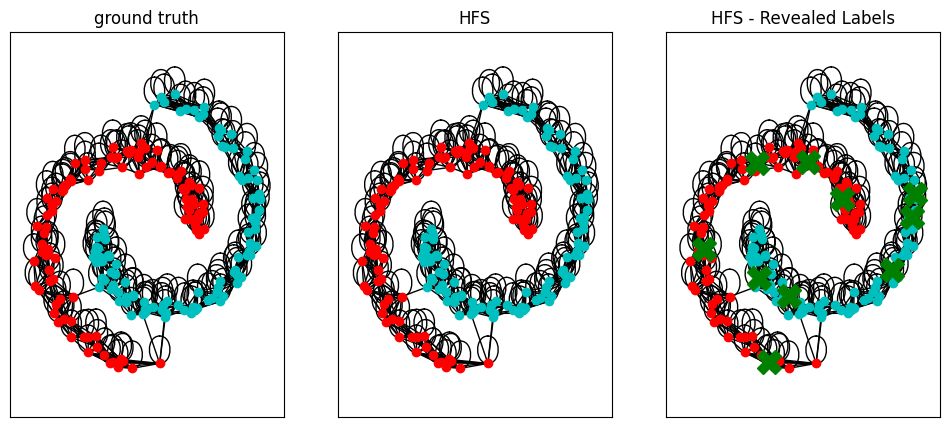

Soft=False, Accuracy=1.0


In [5]:
params['k'] = 10 # connected graph
params['laplacian_normalization'] = 'rw'

seed = 42
X, Y, hard_labels, hard_accuracy = two_moons_hfs(l=10, l_noisy=0, soft=False, dataset='data_2moons_hfs.mat',
                                                 plot=True, seed=seed, **params)

Based on the ablations and results from the previous assignment on the `two_moons` data, we set $k=10$ (ensures connected graph) and use the normalized Laplacian. With these parameters (and $l=10$, $l_{noisy}=0$), we obtain an accuracy of 1.0.

### Question 1.2  - Using `data_2moons_hfs_large.mat`, run `two_moons_hfs` several times with l=4. What can go wrong?

* Tips:
    * When running `two_moons_hfs` several times, don't forget to set `seed=None`

In [32]:
params['k'] = 45 # ensures connected graph 
params['laplacian_normalization'] = 'rw'
error_counter = 0
accuracy = []

np.random.seed(42)
for ii in range(20):
    try:
        X, Y, hard_labels, hard_accuracy = two_moons_hfs(l=4, l_noisy=0, soft=False, 
                                                        dataset='data_2moons_hfs_large.mat',
                                                        plot=False, seed=None, verbose=False, **params)
        accuracy.append(hard_accuracy)
    except AssertionError as e:
        error_counter += 1
        if error_counter == 1:
            print(f"The program has ran into an error: {e}")

if error_counter:
    print(f"Classification has failed {error_counter} times!")
if accuracy:
    print(f"Mean accuracy across {20-error_counter} runs is: {np.mean(accuracy)}")

The program has ran into an error: only one class in training data!
Classification has failed 2 times!
Mean accuracy across 18 runs is: 1.0


From the output above, we can confirm that our program is not fully working, as it ends up twice in the following error: "_Assertion Error: Only one class in training data!_". This happens because, with $l=4$, we select only four samples in a two-class classification problem, which is very small from a probabilistic perspective. More precisely, the probability of selecting four samples that all belong to the same class, in our case, is $\frac{\binom{500}{4} + \binom{500}{4}}{\binom{1000}{4}}\approx 0.124$. This number is consistent with the observed error rate (2 times out of 20 runs, i.e. 0.1) and explains the problem. Based on this, we can conclude that for small values of $l$, there is a high probability of selecting samples from only one class, which would eventually lead to this same issue. Nevertheless, in the remaining successful runs, our method achieves perfect accuracy.

If we want to mitigate this problem, we can simply add the parameter `per_class` to the function `two_moons_hfs` which is then propagated to the function `mask_labels`. When set to `True`, the parameter ensures that $l$ samples will be revealed from each class, and therefore, disables the possibility of having only one class in the training data. We confirm this with the output from the cell below. 

In [ ]:
params['k'] = 45 # ensures connected graph
params['laplacian_normalization'] = 'rw'
error_counter = 0
accuracy = []

np.random.seed(42)
for ii in range(20):
    try:
        # added per_class=True param
        X, Y, hard_labels, hard_accuracy = two_moons_hfs(l=4, l_noisy=0, soft=False, 
                                                        dataset='data_2moons_hfs_large.mat',
                                                        plot=False, seed=None, verbose=False, per_class=True, **params)
        accuracy.append(hard_accuracy)
    except AssertionError as e:
        error_counter += 1
        if error_counter == 1:
            print(f"The program has ran into an error: {e}")

if error_counter:
    print(f"Classification has failed {error_counter} times!")
if accuracy:
    print(f"Mean accuracy across {20-error_counter} runs is: {np.mean(accuracy)}")

Mean accuracy across 20 runs is: 1.0


### Question 1.3 - Using `data_2moons_hfs.mat`, l=10 and l_noisy=5, compare hard HFS to soft HFS. Report the accuracy and comment the results.


====== Dataset: data_2moons_hfs.mat ======
====== Hard HFS =====


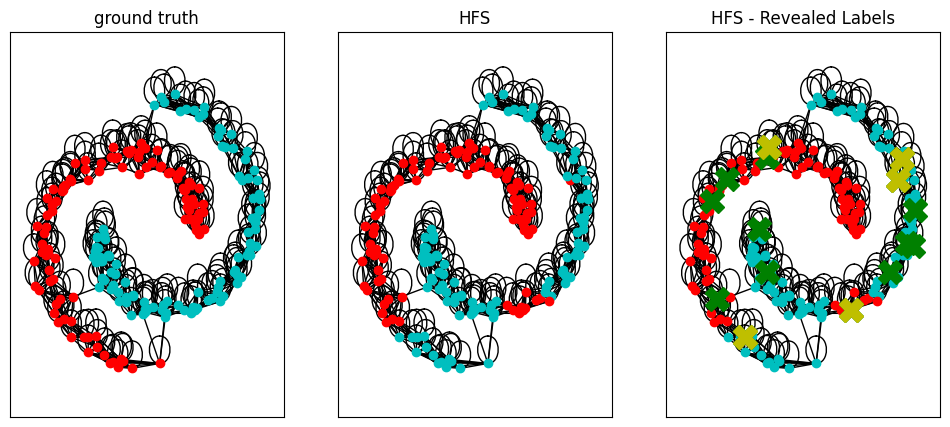

====== Soft HFS =====


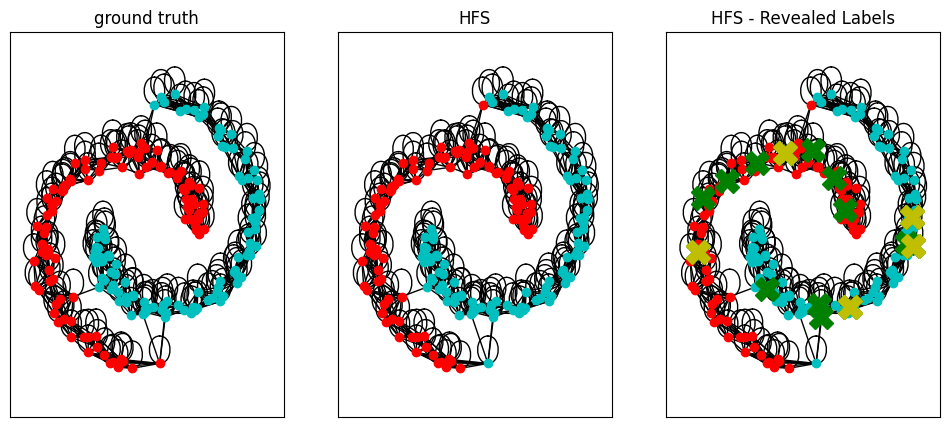

Hard HFS mean accuracy: 0.859
Hard HFS variance accuracy: 0.008414000000000001
Soft HFS mean accuracy: 0.913
Soft HFS variance accuracy: 0.006795999999999999

====== Dataset: data_2moons_hfs_large.mat ======
====== Hard HFS =====


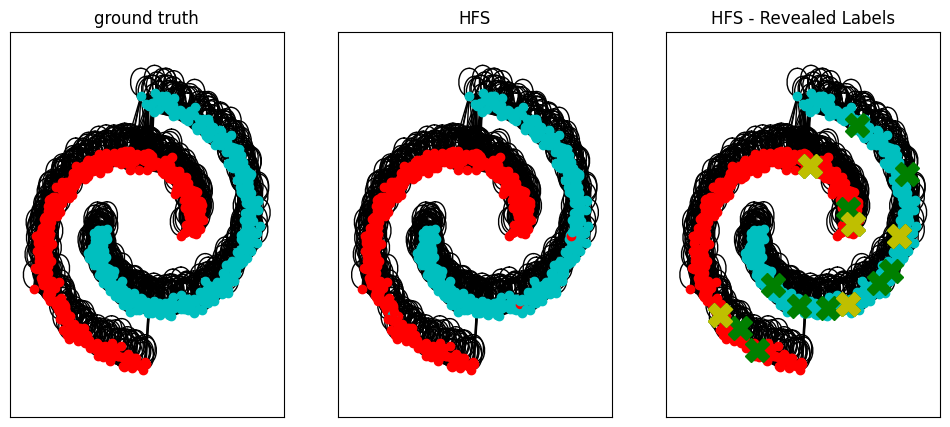

====== Soft HFS =====


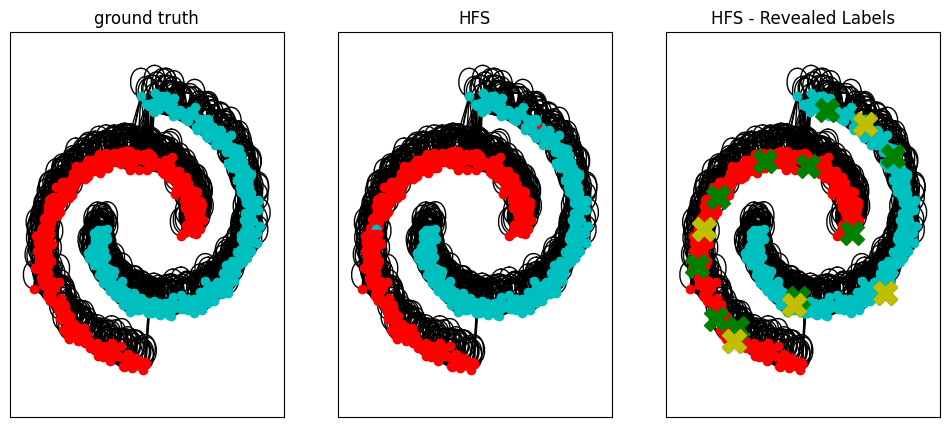

Hard HFS mean accuracy: 0.9684000000000001
Hard HFS variance accuracy: 0.003448240000000001
Soft HFS mean accuracy: 0.9890000000000001
Soft HFS variance accuracy: 0.0003424000000000006


In [ ]:
# Comparing
params['laplacian_normalization'] = 'rw'
params['c_l'] = 0.99
params['c_u'] = 0.01

seed = None  # To run several times with random outcomes, set seed=None. Otherwise, set a seed for reproducibility.
# plot = None 
datasets = ['data_2moons_hfs.mat', 'data_2moons_hfs_large.mat'] # Try also 'data_2moons_hfs_large.mat'

for dataset in datasets:
    hard_accuracies, soft_accuracies = [], []
    
    print(f"\n====== Dataset: {dataset} ======") 
    params['k'] = 10 if 'large' not in dataset else 45

    for ii in range(5):
        plot_hard = True if ii == 0 else False
        if ii == 0:
            print("====== Hard HFS =====")
        X, Y, hard_labels, hard_accuracy = two_moons_hfs(l=10, l_noisy=5, soft=False, dataset=dataset,
                                                        plot=plot_hard, seed=seed, verbose=False, per_class=True, **params)
        hard_accuracies.append(hard_accuracy)

        plot_soft = True if ii == 0 else False
        if ii == 0:
            print("====== Soft HFS =====")
        X, Y, soft_labels, soft_accuracy = two_moons_hfs(l=10, l_noisy=5, soft=True, dataset=dataset,
                                                        plot=plot_soft, seed=seed, verbose=False, per_class=True, **params)
        soft_accuracies.append(soft_accuracy)

    print(f"Hard HFS mean accuracy: {np.mean(hard_accuracies)}")
    print(f"Hard HFS variance accuracy: {np.var(hard_accuracies)}")
    print("="*20)
    print(f"Soft HFS mean accuracy: {np.mean(soft_accuracies)}")
    print(f"Soft HFS variance accuracy: {np.var(soft_accuracies)}")

In the cell above, we run and compare hard HFS and soft HFS on both `data_2moons_hfs.mat` and `data_2moons_hfs_large.mat` datasets. For soft HFS, we set the coefficients of the $C$ matrix to $c_l=0.99$ and $c_u=0.01$ to ensure that labeled samples are given (much) more importance than unlabeled ones. We again use the normalized Laplacian, and set $k=10$ for `data_2moons_hfs.mat` and $k=45$ for `data_2moons_hfs_large.mat` to ensure that graphs are connected. We run the experiments on both datasets for 5 times. The results are shown in the table below:

| Method   | Dataset                   | Mean Accuracy | Variance Accuracy |
|----------|---------------------------|---------------|-------------------|
| Hard HFS | data_2moons_hfs.mat       | 0.8590        | 0.0084            |
| Soft HFS | data_2moons_hfs.mat       | 0.9130        | 0.0067            |
| Hard HFS | data_2moons_hfs_large.mat | 0.9684        | 0.0034            |
| Soft HFS | data_2moons_hfs_large.mat | 0.9890        | 0.0003            |

The results show a high mean accuracy for both methods, with soft HFS outperforming hard HFS. In addition to the mean accuracy, we also choose to evaluate the variance of the accuracy, since lower variance values can indicate a more stable performance across runs. Once again, soft HFS achieves a better score (i.e., lower variance) than hard HFS. 

The performance difference can be explained by how these two methods handle labeled data. Hard HFS enforces a hard constraint (i.e., $f(x)=y$), which means that the labeled data and their labels remain fixed. As a consequence, noisy labels can not be adjusted, even if they are incorrect. Moreover, these incorrect labels can propagate their errors to neighboring unlabeled points, which can ultimately reduce the accuracy. Since the noisy labels, however, may or may not be correct across different runs, and their correctnes and overall results can vary, the variance value is higher. In contrast, soft HFS computes the harmonic function over all points (both labeled and unlabeled) and relaxes the hard constraint. As a result, this method can correct the noisy labels and reduce the error propagation to unlabeled points, which finally improves the results.

Finally, by looking at the plots, we can also visually confirm that soft HFS perform better than hard HFS. 

## 2. Face recognition with HFS

Now, we apply HFS to the task of face recognition, that is, our goal is to classify faces as belonging to different people. Since faces all share common features, it can be a good idea to leverage a large quantity of unlabeled data to improve classification accuracy. In this part of the exercise, you will:

* Extract faces from the images using OpenCV for face detection, and use the same library to apply preprocessing steps;
* Run HFS for classification.

### Implementation

Choose the hyperparameters and run HFS for face recognition, using both the small and large dataset. You can try to change the preprocessing steps (e.g. equalizeHist, GaussianBlur) applied to the images.

**Important**: make sure your HFS code is able to handle more than two classes!

### Question 2.1 - How did you manage to label more than two classes?
To label more than two classes, I used One-Hot Encoding method. In this setting, each label is no longer a scalar, but a $C$-dimensional vector of zeros and ones, where $C$ represents the number of classes (with the column representing unlabeled class being removed). More specifically, for a labeled sample with class label $c \in {1,...,C}$, the one-hot vector contains $1$ at index position $c-1$ and zeros elsewhere (since Python indexing starts at 0, while our class indexing starts at 1). For unlabeled samples, the vector contains only zeros. With this setup, both the labels and harmonic function are now represented as $R^{n \times C}$ matrices.

To predict the labels now, we simply extract the index with the highest score in each sample's vector using the `argmax` function, and then add 1 (to that index) to map it to class indexing (i.e. class=$arg max_{c} f_{ic} + 1$, where $i$ is the index of the sample, and $c$ is the index of the class).


### Question 2.2 - Report the best accuracy you obtained for both (small and augmented) datasets.

* Tips:
    * The small dataset (10 images per person) is loaded with `load_image_data`.
    * Use `load_image_data_augmented` for the augmented dataset (50 images per person). 

To find the best accuracy, we decided to use a grid search over the following parameters:
```
laplacian_normalization = ['unn', 'rw']
k = [5, 7, 10, 15]
var = [1e3, 1e4, 1e5, 1e6]
laplacian_regularization = [0.05, 0.1, 1.0]
c_u = [0.1, 0.05, 0.01, 0.001]  
c_l = [0.9, 0.95, 0.99, 0.999]
```

After several grid search runs, we iteratively tried to enhance the image preprocessing in order to improve the accuracy. We empirically observed that using both `bilateralFilter` and `GaussianBlur` reduced the accuracy, so we removed the `bilateralFilter` and reduced kernel size in `GaussianBlur` to a value of 3. Next, we replaced global histogram equalization in `equalizeHist` with adaptive histogram equalization called Contrast Limited Adaptive Histogram Equalization (CLAHE, [link](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html)). In this method, image is divided into smaller tiles (blocks), which are then histogram equalized. This modification showed the greatest improvement. Finally, we replaced min-max normalization with z-score normalization, which further improved the results.

The best accuracy achieved for the small dataset was 0.87, while for the augmented dataset it was 0.69. Both results were obtained using unnormalized Laplacian with a k-NN graph where $k=7$, the Laplacian regularization parameter set to 0.05, and the variance set to 1000. For the small dataset, coefficients of the $C$ matrix were set to $c_l=0.9$ and $c_u=0.1$, and for the augmented dataset, they were set to $c_l=0.99$ and $c_u=0.01$.

### Question 2.3 - If the accuracy changes when using the augmented dataset, explain why. Does using additional data always increase the performance?

When using the augmented dataset, the accuracy decreases by 0.18. This drop in performance can be explained by examining the proportion of labeled data in each dataset (done in one of the cells below). In the small dataset, 40% of the data is labeled, whereas in the augmented dataset, only 8% is labeled. Therefore, in the second case, we observe that the method relies on a much smaller proportion of supervised samples to infer the labels of a significantly larger number of unlabeled data. As a result, errors propagate more easily and classification becomes more difficult, which ultimately leads to a lower accuracy. 

As we have seen, adding more data does not necessarily increase the performance. Indeed, adding more high quality and labeled data can provide additional useful information that improves the task (e.g. classification). However, if the additional data is uninformative, or mostly unlabeled (thereby recuding the proportion of labeled samples), the method may have less reliable information to learn from, and therefore, performance may decrease instead of improving.

In [17]:
import matplotlib.pyplot as plt
from imageio import imread
import numpy as np
import cv2
import os

from load_images import load_image_data, plot_image_data
from load_images import load_image_data_augmented, plot_image_data_augmented

In [18]:
"""
Define parameters for face recognition with HFS
"""
# We will change and test these parameters in grid search function.
# params_face_rec = {}
# params_face_rec['laplacian_regularization'] = 1.0
# params_face_rec['var'] = 10000.0
# params_face_rec['eps'] = None
# params_face_rec['k'] = None
# params_face_rec['laplacian_normalization'] = 'unn'
# params_face_rec['c_l'] = None
# params_face_rec['c_u'] = None

'\nDefine parameters for face recognition with HFS\n'

In [ ]:
# Function to preprocess the images
# You may try to change it and check the impact on the classification accuracy
def preprocess_image(image):
    """
    Parameters
    ----------
    image : array
        (width, height) array representing a grayscale image
    
    Returns
    -------
        (96, 96) preprocessed image
    """

    output_frame_size = 96   # do not change the output frame size!
    # image = cv2.bilateralFilter(image, 9, 75, 75) # discarder bilateral filter
    clahe = cv2.createCLAHE() # swapped histogram equalization with clahe
    image = clahe.apply(image)
    image = cv2.GaussianBlur(image, (3, 3), 0) # reduced kernel size
    im = cv2.resize(image, (output_frame_size, output_frame_size)).astype(np.float64)
    im -= im.mean()
    im /= im.std()
    image = im
    return image

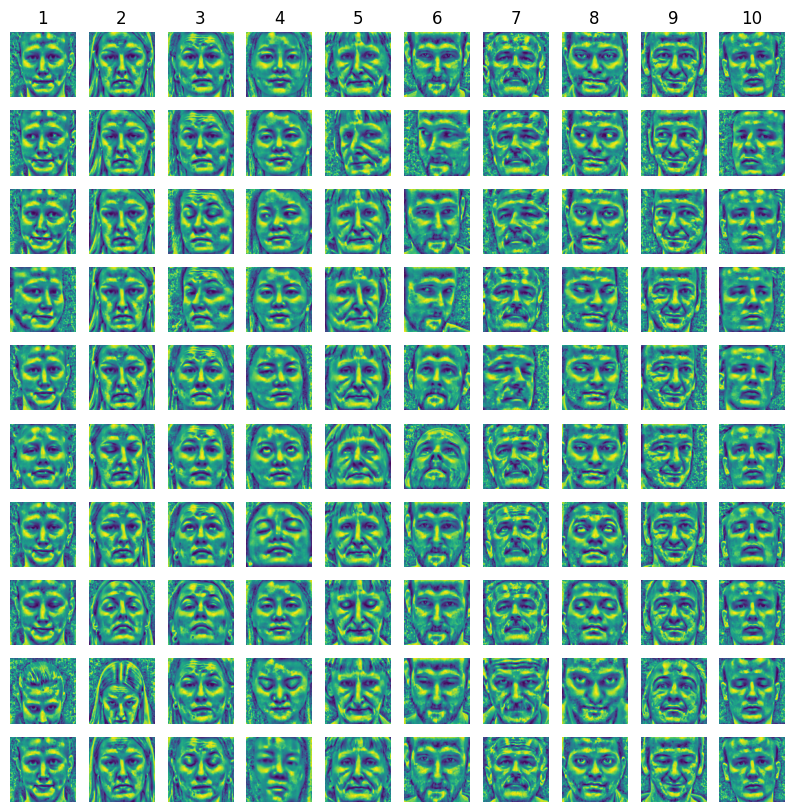

(100, 9216)
[[ 1.  2.  0.  0.  0.  6.  7.  8.  0.  0.]
 [ 1.  2.  0.  4.  0.  0.  7.  0.  0.  0.]
 [ 1.  0.  3.  0.  0.  0.  0.  0.  9.  0.]
 [ 1.  0.  3.  0.  0.  6.  0.  0.  9. 10.]
 [ 0.  0.  0.  4.  5.  6.  0.  8.  0.  0.]
 [ 0.  0.  0.  4.  5.  0.  0.  0.  0.  0.]
 [ 0.  2.  3.  0.  0.  0.  0.  0.  9. 10.]
 [ 0.  0.  0.  0.  5.  6.  7.  0.  0. 10.]
 [ 0.  0.  0.  0.  5.  0.  0.  8.  9. 10.]
 [ 0.  2.  3.  4.  0.  0.  7.  8.  0.  0.]]


In [20]:
# 10 images per person
np.random.seed(456)   # set seed, since labels are masked randomly
images, labels, masked_labels = load_image_data(preprocess_image)

# # 50 images per person
# images_a, labels_a, masked_labels_a = load_image_data_augmented(preprocess_image)
# plot_image_data_augmented(images_a)

# Uncomment below if you want to visualize the images
plot_image_data(images)
print(images.shape)
print(masked_labels.reshape(-1, 10))

In [ ]:
def grid_search_hfs(images, labels, masked):
    best_accuracy = -np.inf

    norms = ['unn', 'rw']
    ks = [5, 7, 10, 15]
    vars = [1e3, 1e4, 1e5, 1e6]
    regs = [0.05, 0.1, 1.0]
    cus = [0.1, 0.05, 0.01, 0.001]  

    for norm in norms:
        for k in ks:
            for var in vars:
                for reg in regs:
                    for c_u in cus:
                        params = {
                            'laplacian_regularization': reg,
                            'var': var,
                            'eps': None,
                            'k': k,
                            'laplacian_normalization': norm,
                            'c_l': 1-c_u,
                            'c_u': c_u,
                        }

                        L = build_laplacian_regularized(
                            images,
                            params['laplacian_regularization'],
                            params['var'],
                            params['eps'],
                            params['k'],
                            params['laplacian_normalization']
                        )

                        predicted_labels, _ = compute_hfs(L, masked, soft=True, **params)
                        accuracy = np.equal(predicted_labels, labels).mean()

                        if accuracy > best_accuracy:
                            best_accuracy = accuracy
                            best_params = params

    return best_accuracy, best_params

In [ ]:
np.random.seed(456)

images, labels, masked_labels = load_image_data(preprocess_image)
best_10_accuracy, best_10_params = grid_search_hfs(images, labels, masked_labels)
print(f"Best accuracy for 10 images per person: {best_10_accuracy}")
print(f"Best params for 10 images per person: {best_10_params}")

Best accuracy for 10 images per person: 0.87
Best params for 10 images per person: {'laplacian_regularization': 0.05, 'var': 1000.0, 'eps': None, 'k': 7, 'laplacian_normalization': 'unn', 'c_l': 0.9, 'c_u': 0.1}


In [ ]:
np.random.seed(456)
images_a, labels_a, masked_labels_a = load_image_data_augmented(preprocess_fn=preprocess_image)
best_50_accuracy, best_50_params = grid_search_hfs(images_a, labels_a, masked_labels_a)
print(f"Best accuracy for 50 images per person: {best_50_accuracy}")
print(f"Best params for 50 images per person: {best_50_params}")

Best accuracy for 50 images per person: 0.69
Best params for 50 images per person: {'laplacian_regularization': 0.05, 'var': 1000.0, 'eps': None, 'k': 7, 'laplacian_normalization': 'unn', 'c_l': 0.99, 'c_u': 0.01}


Accuracy (for 10 images per person) =  0.87


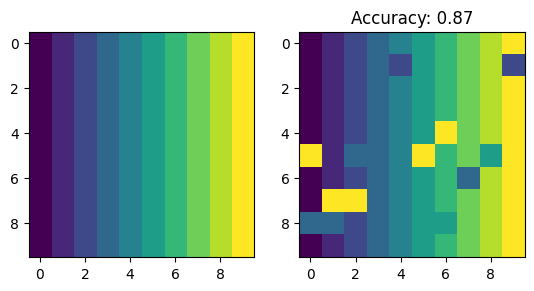

In [29]:
# Run HFS for 10 images per person
np.random.seed(456)
images, labels, masked_labels = load_image_data(preprocess_image)
params_face_rec_10_images = {'laplacian_regularization': 0.05, 'var': 1000.0, 'eps': None, 'k': 7, 'laplacian_normalization': 'unn', 'c_l': 0.9, 'c_u': 0.1}
L = build_laplacian_regularized(
                            images,
                            params_face_rec_10_images['laplacian_regularization'],
                            params_face_rec_10_images['var'],
                            params_face_rec_10_images['eps'],
                            params_face_rec_10_images['k'],
                            params_face_rec_10_images['laplacian_normalization']
                        )
predicted_labels, f = compute_hfs(L, masked_labels, soft=True, **params_face_rec_10_images)
accuracy_10 = np.equal(predicted_labels, labels).mean()
print("Accuracy (for 10 images per person) = ", accuracy_10)

# print(masked_labels)
# print(predicted_labels)
# print(labels)
# Visualize predicted vs true labels
plt.subplot(121)
plt.imshow(labels.reshape((-1, 10)))
plt.subplot(122)
plt.imshow(predicted_labels.reshape((-1, 10)))
plt.title("Accuracy: {}".format(accuracy_10))
plt.show()

Accuracy (for 50 images per person) =  0.69


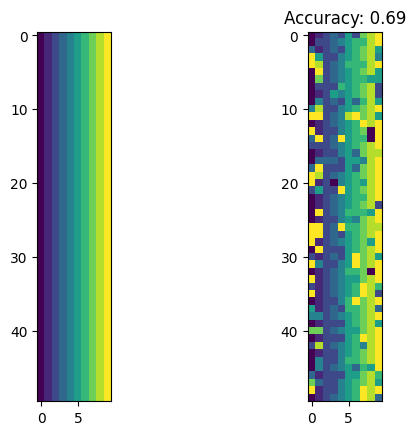

In [21]:
# Run HFS for 10 images per person
np.random.seed(456)
images_a, labels_a, masked_labels_a = load_image_data_augmented(preprocess_fn=preprocess_image)
params_face_rec_50_images = {'laplacian_regularization': 0.05, 'var': 1000.0, 'eps': None, 'k': 7, 'laplacian_normalization': 'unn', 'c_l': 0.99, 'c_u': 0.01}
L = build_laplacian_regularized(
                            images_a,
                            params_face_rec_50_images['laplacian_regularization'],
                            params_face_rec_50_images['var'],
                            params_face_rec_50_images['eps'],
                            params_face_rec_50_images['k'],
                            params_face_rec_50_images['laplacian_normalization']
                        )

predicted_labels, f = compute_hfs(L, masked_labels_a, soft=True, **params_face_rec_50_images)
accuracy_50 = np.equal(predicted_labels, labels_a).mean()
print("Accuracy (for 50 images per person) = ", accuracy_50)

# print(masked_labels)
# print(predicted_labels)
# print(labels)
# Visualize predicted vs true labels
plt.subplot(121)
plt.imshow(labels_a.reshape((-1, 10)))
plt.subplot(122)
plt.imshow(predicted_labels.reshape((-1, 10)))
plt.title("Accuracy: {}".format(accuracy_50))
plt.show()

In [31]:
# Check for labeled/masked images
np.random.seed(456)

_, _, masked_labels = load_image_data(preprocess_image)
labeled_data_percentage = (masked_labels > 0).mean() * 100

_, _, masked_labels_a = load_image_data_augmented(preprocess_fn=preprocess_image)
labeled_data_a_percentage = (masked_labels_a > 0).mean() * 100

print(f"Labeled data percentage for small dataset is {labeled_data_percentage}%")
print(f"Labeled data percentage for augmented dataset is {labeled_data_a_percentage}%")


Labeled data percentage for small dataset is 40.0%
Labeled data percentage for augmented dataset is 8.0%


## 3. Online SSL

Now, instead of having all the data available at once, images will be received online: at each time $t$, a new image $x_t$ is observed and the algorithm has to output a label $y_t$. 

Use the function `create_user_profile` to capture a training set of labeled data (of your face and someone else). The faces will be preprocessed and saved in the folder `data/faces`. They will be loaded by `online_face_recognition`.


### Implementation

Choose the hyperparameters and complete the functions `online_ssl_update_centroids` and `online_ssl_compute_solution`. 

Modify your code to be able to disregard faces it cannot recognize.

* Tips:
    * You can use the functions `build_similarity_graph` and `build_laplacian`.

### Question 3.1 - Attach to this notebook some of the resulting frames of online face recognition. 

* Tips: 
    * You can save the resulting frame and add it to the notebook in a markdown cell as `![title](picture.png)`

Two registered faces were annotated as `empty` and `empty`. In the examples below, we show the frames where the algorithm correctly detected two people in the same frame, and a single person twice.

![Two people correctly detected.](results/two_faces_detected.png)
![empty correctly detected.](results/empty1_face_detected.png)
![empty correctly detected.](results/empty2_face_detected.png)

### Question 3.2 - What strategy did you use to label a face as unknown? Attach to this notebook an example of a unknown face being correctly labeled as unknown.

* Tips
    * If you identify a face as unknown, you can return `[("unknown", score)]` from the function `online_ssl_compute_solution`.

To label the face as unknown, I extracted the maximum score across all label scores (denoted as $max\_score$) and compared it to a predefined threshold of $\tau=0.9$. Then, if $max\_score < \tau$, the face is considered as not sufficiently similar to any of the known ones and therefore classified as unknown, with a score of $1-max\_score$. 

We show below the face of my brother, whose face was not registered before, and is now correctly labeled as unknown.

![Unknown face correctly labeled as unknown.](results/unknown_face.png)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2 as cv
import os
import sys
from scipy.spatial import distance
import scipy.io as sio

from helper_online_ssl import create_user_profile, online_face_recognition

In [2]:
"""
Define parameters for face recognition with HFS
"""
# params_online_ssl = {}
# params_online_ssl['laplacian_regularization'] = 1.0
# params_online_ssl['var'] = 10000.0
# params_online_ssl['eps'] = None
# params_online_ssl['k'] = 15
# params_online_ssl['laplacian_normalization'] = 'unn'
# params_online_ssl['c_l'] = 0.99
# params_online_ssl['c_u'] = 0.01

params_online_ssl = {}
params_online_ssl['laplacian_regularization'] = 0.05
params_online_ssl['var'] = 1000.0
params_online_ssl['eps'] = None
params_online_ssl['k'] = 7
params_online_ssl['laplacian_normalization'] = 'unn'
params_online_ssl['c_l'] = 0.99
params_online_ssl['c_u'] = 0.01

In [24]:
class IncrementalKCenters:
    def __init__(self, labeled_faces, labels, label_names, max_num_centroids=50, learn_new_faces=False, n_pictures=15):
        #  Number of labels
        self.n_labels = max(labels)

        #  Dimension of the input image
        self.image_dimension = labeled_faces.shape[1]

        #  Check input validity
        assert (set(labels) == set(
            range(1, 1 + self.n_labels))), "Initially provided faces should be labeled in [1, max]"
        assert (len(labeled_faces) == len(labels)), "Initial faces and initial labels are not of same size"

        #  Number of labelled faces
        self.n_labeled_faces = len(labeled_faces)

        # Model parameter : number of maximum stored centroids
        self.max_num_centroids = max_num_centroids

        # Model centroids (inital labeled faces). Shape = (number_of_centroids, dimension)
        self.centroids = labeled_faces

        # Centroids labels
        self.Y = labels
        
        # Label names (= user names)
        self.label_names = label_names

        # Variables that are initialized in online_ssl_update_centroids()
        self.centroids_distances = None
        self.taboo = None
        self.V = None
        self.init = True

        # index of x_t (initialized later)
        self.last_face = None

        self.n_pictures = n_pictures
        self.learn_new_faces = learn_new_faces

        if learn_new_faces:
            self.init_params_for_new_faces()

    def init_params_for_new_faces(self):
        """
        Initialization of the parameters for detecting and learning new faces.
        """      
        # store both new unknown faces and their corresponding indices in model.Y
        self.unknown_centroids = []
        self.unknown_indices = []

        self.unknown_distance_threshold = 0.15
        self.new_face_counter = 0

        self.automatic_label = "AutoBob"
    
    def initialize(self):
        """
        Initialization after the first time that the maximum number of centroids is reached.
        """       
        #  Compute the centroids distances
        self.centroids_distances = distance.cdist(self.centroids, self.centroids)

        #  set labeled nodes and self loops as infinitely distant, to avoid merging labeled centroids
        np.fill_diagonal(self.centroids_distances, +np.inf)
        self.centroids_distances[0:self.n_labeled_faces, 0:self.n_labeled_faces] = +np.inf

        # put labeled nodes in the taboo list
        self.taboo = np.array(range(self.centroids.shape[0])) < self.n_labeled_faces

        # initialize multiplicity
        self.V = np.ones(self.centroids.shape[0])


    def online_ssl_update_centroids(self, face):
        """
        TO BE COMPLETED

        Update centroids, multiplicity vector V, labels Y.
        
        Note: In Y, set label to 0 for unlabeled faces.

        Parameters
        ----------
        face : array
            New sample
        
        Returns
        --------
        List with the scores for each possible label:
            [(label_1, score_1), (label_2, score_2), ...]
        """

        assert (self.image_dimension == len(face)), "new image not of good size"

        # Case 1: maximum number of centroids has been reached.
        if self.centroids.shape[0] >= self.max_num_centroids + 1:
            if self.init:
                #  Initialization after the first time that the maximum number of centroids is reached
                self.initialize()
                self.init = False
            """
            Find c_rep and c_add following Algorithm 1.
            
            - c_1, c_2 = two closest centroids (minimum distance) such that at least one of them is not in self.taboo.
            - c_rep = centroid in {c_1, c_2} that is in self.taboo. If none of them is in self.taboo, c_rep is the one
                      with largest multiplicity.
            - c_add = centroid in {c_1, c_2} that is not c_rep.
            """
            c_rep, c_add = None, None

            min_dist = np.inf
            n_centroids = self.centroids_distances.shape[0]

            for i in range(n_centroids):
                for j in range(i + 1, n_centroids):
                    if self.taboo[i] and self.taboo[j]:
                        continue

                    dist = self.centroids_distances[i, j]
                    if dist < min_dist:
                        min_dist = dist
                        c1, c2 = i, j

            if self.taboo[c1]:
                c_rep, c_add = c1, c2
            elif self.taboo[c2]:
                c_rep, c_add = c2, c1
            elif self.V[c2] <= self.V[c1]:
                c_rep, c_add = c1, c2
            else:
                c_rep, c_add = c2, c1

            """
            Update data structures: self.centroids and self.V
            """

            self.V[c_rep] += self.V[c_add]
            self.centroids[c_add] = face
            self.V[c_add] = 1
            # self.Y[c_add] = 0

            """
            Update lists for unknown faces handling
            """
            if self.learn_new_faces:
                # if the replaced centroid was an unknown face, we need to remove it from the unknown lists
                unknown_indices = np.asarray(self.unknown_indices)
                unknown_to_keep = unknown_indices != c_add

                self.unknown_centroids = list(np.asarray(self.unknown_centroids)[unknown_to_keep])
                self.unknown_indices = list(unknown_indices[unknown_to_keep])
            """
            Update the matrix containing the distances.
            """
            dist_row = distance.cdist(np.array([self.centroids[c_add]]), self.centroids)[0]
            dist_row[c_add] = +np.inf
            self.centroids_distances[c_add, :] = dist_row
            self.centroids_distances[:, c_add] = dist_row
            self.last_face = c_add

        # Case 2: create new centroid with face
        # Remark: the multiplicities vector self.V is initialized in self.initialize()
        else:
            current_len = len(self.centroids)
            self.Y = np.append(self.Y, 0)
            self.centroids = np.vstack([self.centroids, face])
            self.last_face = self.centroids.shape[0] - 1

    def online_ssl_compute_solution(self):
        """
        TO BE COMPLETED.

        Returns a prediction corresponding to self.last_face.
        """

        # Multiplicity matrix
        if self.init:
            V = np.diag(np.ones(self.centroids.shape[0]))
            self.last_face = self.centroids.shape[0] - 1
        else:
            V = np.diag(self.V)
            
        # Build quantized graph and its regularized Laplacian
        
        W_tilde = build_similarity_graph(
            self.centroids, 
            params_online_ssl['var'],
            params_online_ssl['eps'],
            params_online_ssl['k']
        )
        W = V @ W_tilde @ V
        L = build_laplacian(W, params_online_ssl['laplacian_normalization'])
        Q = L + params_online_ssl['laplacian_regularization'] * np.eye(L.shape[0]) # regularized Laplacian

        # Compute the hard HFS solution f. 
        labels, f = compute_hfs(Q, self.Y, soft=False, **params_online_ssl)

        # Return the score for each possible label
        num_classes = len(np.unique(self.Y))-1 
        label_scores = []
        for ii in range(num_classes):
            label = self.label_names[ii]
            score = f[self.last_face, ii]
            label_scores.append((label, score))

        max_score = np.max([score for _, score in label_scores])
        if max_score < 0.9:
            return [("unknown", 1-max_score)]

        return label_scores
    
    def check_and_add_new_face(self, face):
        """
            Function to check if a new unknown face has been seen enough times to be added as a new face.
            Called inside the online_face_recognition function, when new face is assigned an unknown label.

            Returns the label and color for the new face if it has been added.
            Otherwise returns "unknown" and a default unknown color.
        """
        self.unknown_centroids.append(face)
        self.unknown_indices.append(self.last_face) # append by index position in model.Y/last_face

        # before computing the distances, we need to scale both face and unknown centroids
        face_norm = face / (np.linalg.norm(face) + 1e-12) 
        U = np.asarray(self.unknown_centroids) # var for keeping unknown centroids as np array because of cdist
        U = U / (np.linalg.norm(U, axis=1, keepdims=True) + 1e-12)
        
        # compute similarity using the distance between the unknown centroids and the new face
        # if the distance is smaller than a threshold, we consider it a match
        unknown_distances = distance.cdist(U, face_norm[None, :], metric="cosine").reshape(-1)
        matched_unknown_faces = unknown_distances < self.unknown_distance_threshold

        if np.sum(matched_unknown_faces) >= self.n_pictures: # if there are enough unknown faces saved
            new_face_id = int(np.max(self.Y) + 1) # same as ll_idx, just for unknown
            self.new_face_counter += 1
            new_face_label = f"{self.automatic_label}_{self.new_face_counter}"

            # relabeling logic
            indices_to_relabel = np.asarray(self.unknown_indices)[matched_unknown_faces]
            self.Y[indices_to_relabel] = new_face_id

            # add newest face to taboo
            if self.taboo is not None:
                self.taboo[self.last_face] = True

            # remove newly adopted faces from unknown list
            keep_unknown_faces = ~matched_unknown_faces
            self.unknown_centroids = list(np.asarray(self.unknown_centroids)[keep_unknown_faces])
            self.unknown_indices = list(np.asarray(self.unknown_indices)[keep_unknown_faces])
            
            # add new label to old
            self.label_names.append(new_face_label)

            # update model states
            # self.n_labeled_faces += 1
            self.n_labels += 1

            return new_face_label, [(0, 255, 0), (255, 0, 0), (0, 0, 255)][new_face_id % 3]
        
        # if not seen enough times, keep as unknown
        return "unknown", (100, 100, 100)

In [ ]:
# create_user_profile('empty1')         # choose your names here :)
# create_user_profile('empty2')
online_face_recognition(['', ''], IncrementalKCenters, n_pictures=15)

Profile found with 15 images.
Profile found with 15 images.
saved
Image saved at results\correct_frame_0.png


### Question 4.1 - You can now classify faces as either known (i.e. belong to a class) or unknown (i.e. belong to no class). How would you modify the algorithm to automatically learn to classify new classes? That is, how can you modify the algorithm so that faces that appear unfrequently are labeled as unknown, but once a specific face has been seen enough times it gets assigned an automatic label (e.g. AutoBob) and from that point it is treated as a new class. 

* Tips: 
    * Think back to the idea of incremental clustering as unsupervised classification

We will modify the existing approach to automatically learn to classify new classes within the `online_face_recognition` function and `IncrementalKCenters` class. We specifically introduced `learn_new_faces` flag that controls whether the algorithm operates in its original form or uses this extended behavior. The code logic is implemented through `IncrementalKCenters.check_and_add_new_face` method. In what follows, we describe this modification in detail.

The algorithm is first extended to store detected unknown faces and their corresponding centroid indices in two lists, where each newly detected unknown face is appended. Additionally, in the `online_ssl_update_centroids` method, when a centroid index `c_add` is replaced, we remove that index and its corresponding face from the aformentioned unknown lists. This prevents incorrect class assignments when the number of maximum centroids is reached. 

Next, we model the frequency of an unknown face by measuring how many of previously stored unknown faces are similar to the current one. This similarity is evaluated using a distance cosine metric (the same way as before with `distance.cdist`) between the normalized current face and the list of stored and normalized unknown faces. The frequency is then obtained by counting how many faces saitisfy the thresholding condition ($\tau=0.15$) on their corresponding distances. 

We then define that the unknown face has been seen enough times to be automatically labeled when it appears at least 15 times, which is consistent with the number of images previously required to create a user profile. If the frequency is less than 15, the face stays labeled as "unknown" in the same way as before. Otherwise, we assign it to a new class by giving it an automatic label `AutoBob_counter-of-new-classes`. Once created, we update `Y` with a newly class' id, add the new label to the list of known labels (i.e., `label_names`), and set the `taboo` flag to `True` for the centroid index that corresponds to the current face. The previously stored unknown faces corresponding to the current one are also removed from the list of unknowns. From this point onward, the so far unknown face is treated as a regular, known class.

Below, we show how our modification works in practice, by assigning a new class to the unknown face from the previous qeustion.

![New automatically labeled class](results/from_unknown_to_new_face.png)

In [ ]:
# from helper_online_ssl import create_user_profile, online_face_recognition
online_face_recognition(['', ''], IncrementalKCenters, n_pictures=15, learn_new_faces=True)

Profile found with 15 images.
Profile found with 15 images.


### Question 4.2 - In class we considered different kinds of metric for (semi) supervised learning. Looking at the face classification task, try to quantify how the offline-online, exact-quantized, and inductive-transductive axes influence each other. In particular given $l$ labeled faces, $u = N - l$ unlabeled faces, and $m$ extra/test faces design an experimental study to quantify these trade-offs, both in terms of transductive and inductive error, as well as online/batch error. Examples of combinations that can be used to study these axes are:
* Supervised vs Semi-supervised
    * A comparison between a supervised learner (of your choice) trained on the $l$ labeled faces and a semi-supervised learner (of your choice) trained on the $l + u$ labeled and unlabeled faces
    * A comparison between a supervised learner (of your choice) trained on the $N$ labeled and unlabeled (you reveal everything here) faces and a semi-supervised learner (of your choice) trained on the $l + u$ labeled and unlabeled faces.
* Inductive vs Transductive
    * A comparison between a supervised learner (of your choice) trained on the $l$ labeled faces and a semi-supervised learner (of your choice) trained on the $l + u$ labeled and unlabeled faces evaluated on the $N$ revealed points and then on the $m$ unrevealed points.
* Supervised vs Semi-supervised and Inductive vs Transductive
    * A comparison between a supervised learner (of your choice) trained on the $N$ labeled and unlabeled (you reveal everything here) faces and a semi-supervised learner (of your choice) trained on the $l + u$ labeled and unlabeled faces, evaluated on the $N$ revealed points and then on the $m$ unrevealed points.
* Online vs Batch
    * A comparison between a supervised learner (of your choice) trained on the $N$ labeled faces and an online supervised learner (of your choice) trained revealing the $N$ labels one at a time
* Exact vs Quantized
    * A comparison between a semi-supervised learner (of your choice) trained on the $N$ labeled and unlabeled (you reveal everything here) faces using a certain memory budget, and the same learner with a constrained memory budget.
* Exact vs Quantized and Online vs Batch and Inductive vs Transductive
    * A comparison between a semi-supervised online learner (of your choice) trained with and without quantization, evaluated both on the $N$ faces revealed during training, and $m$ faces unrevealed. You can further compare the online performance of the learner against the performance of an "hindsight" learner that saw the labels all at once

Before conducting the experiments, we first have to set up our dataset. We do so by building on top of augmented face dataset, and, instead of creating a single dataset, we generate multiple variants with different labeled to unlabeled face ratio (from 0.1 to 0.9). This is done in order to better analyze how the amount of supervision affects performance in semi-supervised (SSL) approaches, but also, how SSL approach compares to the supervised (SL) one depending on the labeled ratio. 

For each dataset, we store all labeled and unlabeled training samples, as well as the test samples. Each dataset contains 10 classes (10 people), resulting in a total of 500 samples (50 per person). The training set size, $N$, is always set to 400 samples (i.e., 80% of the total data), while the remaining $m=100$ samples are reserved for testing. The numbers of labeled and unlabeled samples, $l$ and $u$, are determined according to the corresponding ratio. We also perform a stratified split per class so that the labeled & unlabeled, an training & test sets all contain an equal number of samples from each class.

In [ ]:
def create_datasets(n_person=10):
    """
    Function to create datasets for face recognition with various labeled/unlabeled ratio.

    Parameters
    ----------
    n_person : int
        Number of people (classes) in dataset.
    """
    np.random.seed(456)

    datasets = {}

    dataset_size = n_person * 50 # each person has 50 faces
    n_train = int(dataset_size * 0.8) # split 80%/20%

    ratio_labeled_to_unlabeled = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

    for ratio in ratio_labeled_to_unlabeled:
        l = int(n_train * ratio / n_person) # number of revealed labels
        X, y, mask = load_image_data_augmented(n_person=n_person, l=l, preprocess_fn=preprocess_image)

        # count number of total labeled, unlabeled in train set, and number of samples in test
        n_labeled = np.sum(mask != 0)
        n_unlabeled_train = n_train - int(n_labeled)
        n_test = dataset_size - n_train

        # collect labeled and unlabeled for X and Y
        X_labeled, X_unlabeled = X[np.where(mask != 0)[0]], X[np.where(mask == 0)[0]]
        y_labeled, y_unlabeled = y[np.where(mask != 0)[0]], y[np.where(mask == 0)[0]]

        # since n_labeled < n_train, we immediatelly take the part of training set as labeled
        X_train_labeled = X_labeled
        y_train_labeled = y_labeled

        # the remaining training set is consisted of unlabeled samples
        # we here handle the stratified split per class
        train_unlabeled_indices = []
        test_indices = []
        for c in range(1, n_person + 1):
            class_indices = np.where(y_unlabeled == c)[0]
            np.random.shuffle(class_indices)
            n_train_class = n_unlabeled_train // n_person
            train_unlabeled_indices.extend(class_indices[:n_train_class])
            test_indices.extend(class_indices[n_train_class:n_train_class + n_test // n_person])

        train_unlabeled_indices = np.array(train_unlabeled_indices)
        test_idx = np.array(test_indices)

        X_train_unlabeled = X_unlabeled[train_unlabeled_indices]
        y_train_unlabeled = y_unlabeled[train_unlabeled_indices]

        # data to train the model on N samples
        X_N = np.concatenate([X_train_labeled, X_train_unlabeled])
        y_N = np.concatenate([y_train_labeled, y_train_unlabeled]) 

        # label data for SSL model training
        y_train_ssl = np.concatenate([y_train_labeled, -1 * np.ones(len(y_train_unlabeled), dtype=int)])

        X_test = X_unlabeled[test_idx]
        y_test = y_unlabeled[test_idx]

        datasets[ratio] = {
            "X_train_labeled": X_train_labeled,
            "y_train_labeled": y_train_labeled,
            "X_train_unlabeled": X_train_unlabeled,
            "y_train_unlabeled": y_train_unlabeled,
            "X_N": X_N,
            "y_N": y_N,
            "X_test": X_test,
            "y_test": y_test,
            "y_train_ssl": y_train_ssl,
            "params": {
                "n_person": n_person,
                "ratio": ratio,
                "N": n_train,
                "l": n_labeled,
                "u": n_train-n_labeled,
                "m": dataset_size-n_train
            }
        }

    return datasets

face_datasets = create_datasets()

### Supervised vs Semi-supervised and Inductive vs Transductive

In what follows, we examine the performance on $N$ revealed points (i.e., transductive) and  $m$ unrevealed points (i.e., inductive) of SL model trained on either $l$ or $N$ samples and SSL model trained on $l+u$ samples. We use `sklearn.svm.SVC` as our SL model. As its SSL counterpart, we use `sklearn.semi_supervised.LabelPropagation`.

In [56]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.semi_supervised import LabelPropagation
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

In the cell below, we train and evaluate all of our SVM and LabelPropagation models for each dataset configuration. Specifically, we do the following:
- Normalization:
    - Apply z-score normalization for each dataset and model using `StandardScalar`.
- Training phase:
    - Train a SL SVM model on $l$ samples. We denote this model in following paragraphs as SVM (l).
    - Train a second SL SVM model on all $N$ samples. Again, we denote this model as SVM (N).
    - Train a SSL LabelPropagation model on $l+u$ samples.
- Evaluation phase:
    - Evaluate all trained models transductively, i.e., on all $N$ revealed samples, using F1 score.
    - Evaluate all trained models inductively, i.e., on $m$ unseen samples, using F1 score.

In [54]:
results = {
    "sl_l_vs_ssl_lu": {},
    "sl_N_vs_ssl_lu": {},
}

for ratio, dataset in face_datasets.items():
    # train all models on all possible data

    # SL on l
    svm_l = make_pipeline(
        StandardScaler(),
        SVC()
    )
    svm_l.fit(dataset["X_train_labeled"], dataset["y_train_labeled"])

    # SL on N 
    svm_N = make_pipeline(
        StandardScaler(),
        SVC()
    )
    svm_N.fit(dataset["X_N"], dataset["y_N"])

    # SSL on N with y = -1 for unlabeled
    label_propagation = make_pipeline(
        StandardScaler(),
        LabelPropagation(kernel="rbf", gamma=0.02)
    )
    label_propagation.fit(dataset["X_N"], dataset["y_train_ssl"])

    # obtain all possible predictions:
    predictions = {
        "svm_l_transductive": svm_l.predict(dataset["X_N"]),
        "svm_l_inductive": svm_l.predict(dataset["X_test"]),
        "svm_N_transductive": svm_N.predict(dataset["X_N"]),
        "svm_N_inductive": svm_N.predict(dataset["X_test"]),
        "label_propagation_transductive": label_propagation.predict(dataset["X_N"]),
        "label_propagation_inductive": label_propagation.predict(dataset["X_test"]),
    }

    # experiment on SL SVM on l vs SSL label propagation trained on l+u
    results["sl_l_vs_ssl_lu"][ratio] = {
        "svm_transductive": f1_score(dataset["y_N"], predictions["svm_l_transductive"], average="weighted"),
        "svm_inductive": f1_score(dataset["y_test"], predictions["svm_l_inductive"], average="weighted"),
        "label_propagation_transductive": f1_score(dataset["y_N"], predictions["label_propagation_transductive"], average="weighted"),
        "label_propagation_inductive": f1_score(dataset["y_test"], predictions["label_propagation_inductive"], average="weighted"),
    }

    # experiment on SL SVM on N vs SSL label propagation trained on l+u
    results["sl_N_vs_ssl_lu"][ratio] = {
        "svm_transductive": f1_score(dataset["y_N"], predictions["svm_N_transductive"], average="weighted"),
        "svm_inductive": f1_score(dataset["y_test"], predictions["svm_N_inductive"], average="weighted"),
        "label_propagation_transductive": f1_score(dataset["y_N"], predictions["label_propagation_transductive"], average="weighted"),
        "label_propagation_inductive": f1_score(dataset["y_test"], predictions["label_propagation_inductive"], average="weighted"),
    }


After computing the evaluation results for all datasets, we will visualize them on two plots. In both plots, the x-axis represents the labeled ratio $l/N$, and they y-axis represents the F1 score. More specifically:
1. The first plot compares an SL SVM trained on $l$ samples and SSL LabelPropagation trained on $l+u$ samples, both transductively and inductively.
2. The second plot compares an SL SVM trained on $N$ samples and SSL LabelPropagation trained on $l+u$ samples, both transductively and inductively.

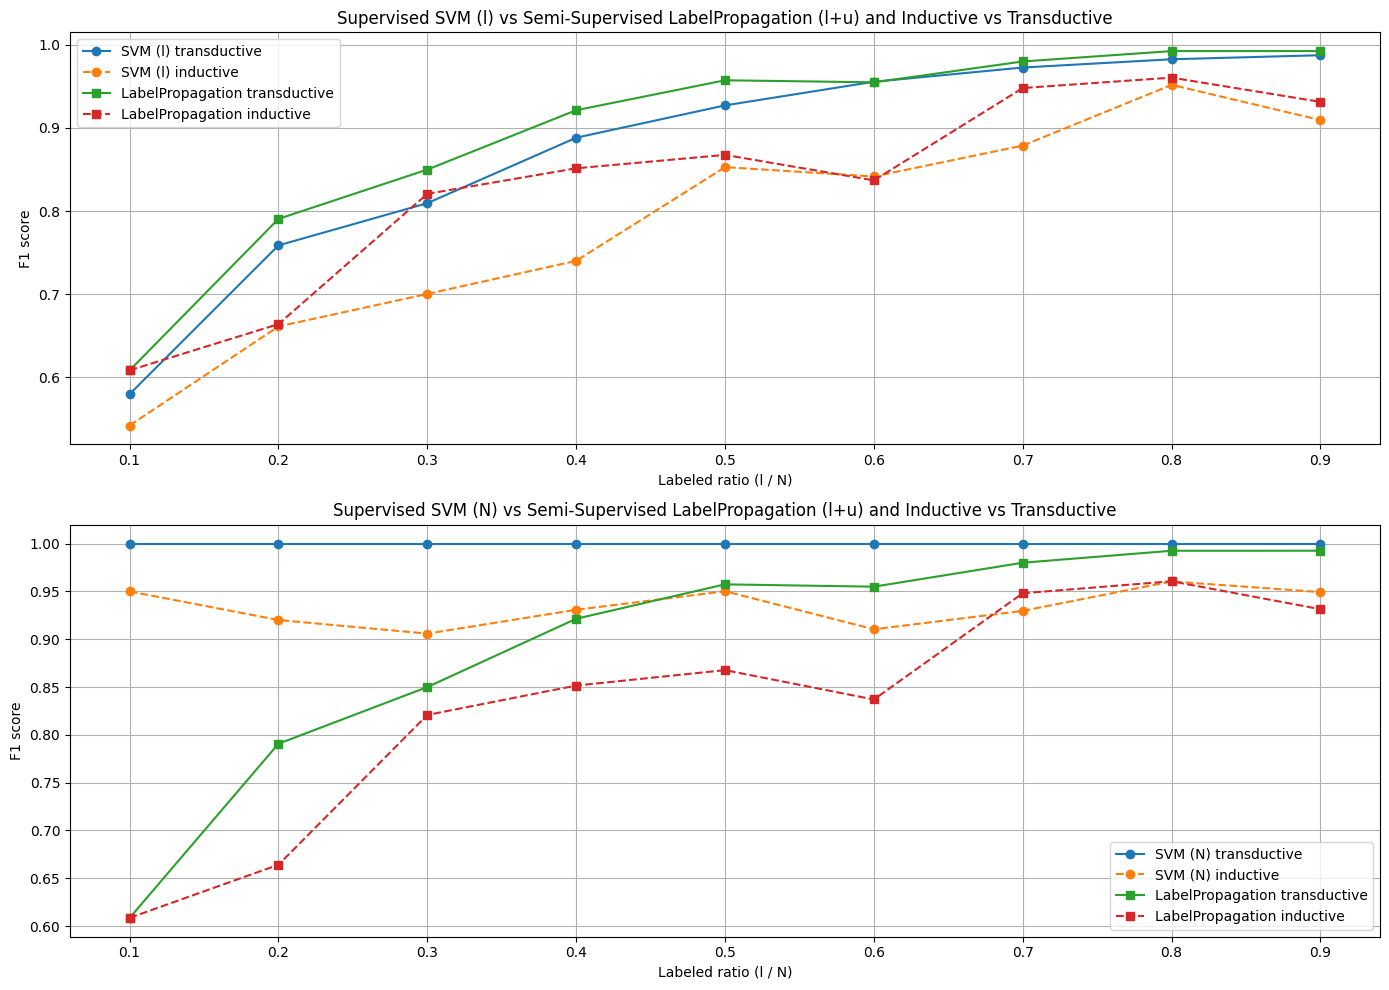

In [55]:
ratios = list(results["sl_l_vs_ssl_lu"].keys())

def get_scores(result, model, ratios):
    return [results[result][ratio][model] for ratio in ratios]

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Plot SL SVM trained on the l samples, SSL LabelPropagation trained on l+u samples both on transductive and inductive
ax = axes[0]
ax.plot(ratios, get_scores("sl_l_vs_ssl_lu", "svm_transductive", ratios), marker="o", linestyle="-", label="SVM (l) transductive")
ax.plot(ratios, get_scores("sl_l_vs_ssl_lu", "svm_inductive", ratios), marker="o", linestyle="--", label="SVM (l) inductive")
ax.plot(ratios, get_scores("sl_l_vs_ssl_lu", "label_propagation_transductive", ratios), marker="s", linestyle="-", label="LabelPropagation transductive")
ax.plot(ratios, get_scores("sl_l_vs_ssl_lu", "label_propagation_inductive", ratios), marker="s", linestyle="--", label="LabelPropagation inductive")
ax.set_title("Supervised SVM (l) vs Semi-Supervised LabelPropagation (l+u) and Inductive vs Transductive")
ax.set_xlabel("Labeled ratio (l / N)")
ax.set_ylabel("F1 score")
ax.legend()
ax.grid(True)

# Plot SL SVM trained on the N samples, SSL LabelPropagation trained on l+u samples both on transductive and inductive
ax = axes[1]
ax.plot(ratios, get_scores("sl_N_vs_ssl_lu", "svm_transductive", ratios), marker="o", linestyle="-",  label="SVM (N) transductive")
ax.plot(ratios, get_scores("sl_N_vs_ssl_lu", "svm_inductive", ratios), marker="o", linestyle="--", label="SVM (N) inductive")
ax.plot(ratios, get_scores("sl_N_vs_ssl_lu", "label_propagation_transductive", ratios), marker="s", linestyle="-", label="LabelPropagation transductive")
ax.plot(ratios, get_scores("sl_N_vs_ssl_lu", "label_propagation_inductive", ratios), marker="s", linestyle="--", label="LabelPropagation inductive")
ax.set_title("Supervised SVM (N) vs Semi-Supervised LabelPropagation (l+u) and Inductive vs Transductive")
ax.set_xlabel("Labeled ratio (l / N)")
ax.set_ylabel("F1 score")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()

##### Supervised vs Semi-supervised and Inductive vs Transductive: SVM (l) vs LabelPropagation
As shown in the first plot, in the transductive setting, the SSL model consistently outperforms the SL model. Both models start with a relatively low F1 score and then steadily improve as the labeled ratio increases. Toward the last ratios, both models achieve near perfect scores. This behavior was expected, as the ratio directly determines the amount of data that SL model is trained on and also the amount of supervision that SSL model recieves. Similarly, we observe that performance gap between the SSL and SL model is largest for lower ratio values (i.e., for $l/N \le 0.5$). As the ratio increases, this gap decreases, which indicates that for $l/N \approx 1$, the SL model behaves similarly to the SSL one, and moreover, that the advantage of additional unlabeled data becomes negligible.

In the case of inductive task, the SSL model shows an even larger advantage over the SL model, especially when $l/N \le 0.4$. The SSL model keeps the F1 score in range of 0.8-1.0 for most of the datasets, and again, achieves near-perfect scores for highest ratio values. On the other hand, the SL model reaches a score of 0.8 only when $l/N \ge 0.5$. This trend of the SL model was expected, due to broader and larger number of training samples and therefore, reduced risk of overfitting. In the end, this experiment indicates that additional data, even if it is unlabeled, can indeed improve the generalization performance. 

Finally, from the results of our first experiment, we can conclude that increasing the amount of labeled data benefits both models. When the two are compared, our results indicate that incorporating unlabeled data in training improves both the transductive and inductive (i.e., generalization) performance, especially when labeled ratio is small.

##### Supervised vs Semi-supervised and Inductive vs Transductive: SVM (N) vs LabelPropagation
We will now concentrate on the second plot. First, we note that the performance of the SL model, both in the inductive and transductive settings, is not directly connected to the labeled ratio $l/N$. This is because the dataset between different ratios can slightly differ, yet, the amount of training data across all remains the same. Moreover, we note that the results from our SSL model remain unchanged compared to the previous experiment. 

Unlike before, the SL model now consistently achieves a perfect transductive performance. Previously, the SL model was trained on only $l$ samples and evaluated on $N$ samples, meaning that its trasnductive evaluation actually behaved like an inductive one. In the present case, the model is trained and evaluated on the same data (i.e., all $N$ samples), which explains its perfect results. As for the SSL model, its performance now is lower than the one of the SL model, especially for lower ratios. As the ratio increases, this gap is smaller, and when $l/N \ge 0.6$, the SSL performance is really close to the SL's one.

In the inductive setting, the SL model mostly achieves F1 scores between 0.9 and 1.0. The improvement of the SL model comes from the fact that it has more data to train on, and therefore, can generalize better. Similar to the transductive setting, up to $l/N \le 0.6$, the SL model outperforms the SSL one. However, for higher ratios, the SSL model achieves similar, or even higher scores. This suggests that, when a sufficiently large number of samples is labeled, adding unlabeled data can provide a small improvement in generalization.

In conclusion, we can confirm that when all training data is fully labeled, the SL model provides the highest performance, especially when the labaled ratio is low. Yet, we must also note that, as this ratio increases, the SSL model achieves comparable results, and may even slightly improve the inductive performance, which again shows the impact of the unlabeled data. 

### Batch vs Online

As another experiment, we compare batch and online learning methods trained on all $N$ training samples. For batch learning, we use a `sklearn.svm.LinearSVC` model (linear SVM), and as its online counterpart, we use `sklearn.linear_model.SGDClassifier` with loss='hinge', which gives a linear SVM (i.e., it similarly optimizes the same objective). The first model uses batch optimization, whereas the second one uses stochastic gradient descent.

Since both models always train on all $N$ samples, the labeled to unlabeled ratio is not relevant in this case. Instead, we use 3 different datasets (different ratio datasets) to evaluate both models across multiple runs (3 runs), and therefore, give a better overview. We evalute models both transductively and inductively, with the F1 score metric, as before.

In [ ]:
all_batch_transductive_score = []
all_batch_inductive_score = []
all_online_transductive_final_score = []
all_online_inductive_final_score = []

# ratio does not matter here, but we still use the same approach to find the average scores across runs
for i, (ratio, dataset) in enumerate(face_datasets.items()):
    # we take only three datasets
    if len(face_datasets.keys()) - i >= 4:
        continue

    # LinearSVC batch model 
    batch_model = LinearSVC()
    batch_model.fit(dataset["X_N"], dataset["y_N"])
    
    # predict with batch model
    all_batch_transductive_score.append(f1_score(dataset["y_N"], batch_model.predict(dataset["X_N"]), average="weighted"))
    all_batch_inductive_score.append(f1_score(dataset["y_test"], batch_model.predict(dataset["X_test"]), average="weighted"))

    # SGDClassifier with hinge loss gives a linear SVM with a possibility of online learning
    online_model = SGDClassifier(loss="hinge", random_state=42)        

    # keep track of evaluations through all steps
    online_transductive_scores, online_inductive_scores = [], []                  

    for j, index in enumerate(range(dataset["X_N"].shape[0])):
        X_single = dataset["X_N"][index].reshape(1, -1)    
        y_single = dataset["y_N"][index].reshape(1)

        online_model.partial_fit(X_single, y_single, classes=np.unique(dataset["y_test"]))

        # if j % 2 == 0:
        online_transductive_scores.append(f1_score(dataset["y_N"], online_model.predict(dataset["X_N"]), average="weighted"))
        online_inductive_scores.append(f1_score(dataset["y_test"], online_model.predict(dataset["X_test"]), average="weighted"))

    # keep the final score only 
    all_online_transductive_final_score.append(online_transductive_scores[-1])
    all_online_inductive_final_score.append(online_inductive_scores[-1])

print("Online vs Batch Results")
print("=======================")
print(f"Batch transductive F1 score: {np.mean(all_batch_transductive_score)}")
print(f"Batch inductive F1 score: {np.mean(all_batch_inductive_score)}")
print("=======================")
print(f"Online transductive F1 score: {np.mean(all_online_transductive_final_score)}")
print(f"Online inductive F1 score: {np.mean(all_online_inductive_final_score)}")
    

c:\Users\Nemanja\Desktop\simulation-try\lib\site-packages\sklearn\svm\_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
c:\Users\Nemanja\Desktop\simulation-try\lib\site-packages\sklearn\svm\_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Online vs Batch Results
Batch transductive F1 score: 1.0
Batch inductive F1 score: 0.9532345136006463
Online transductive F1 score: 0.9552541820688698
Online inductive F1 score: 0.8475733521212446


As it can be seen, both models achieve high F1 scores, with the batch model outperforming the online one on both transductive and inductive tasks. The gap in performance is more pronounced in the inductive task, while the difference in transductive performance is relatively small. 

Since this is a smaller scale experiment, we want to emphasize that the choice between the two models in practice depends on the task and the data. For smaller datasets, batch models, such as LinearSVC, will generally perform better and are the preferable option. For large datasets, however, these models can become slow and memory heavy. Online models based on stochastic gradient descent (e.g., SGDClassifier) mitigate these issues, and offer a lower memory usage and much faster optimization.

For the final part, we also plot the evaluation at each step of our online model on both transductive and inductive tasks.

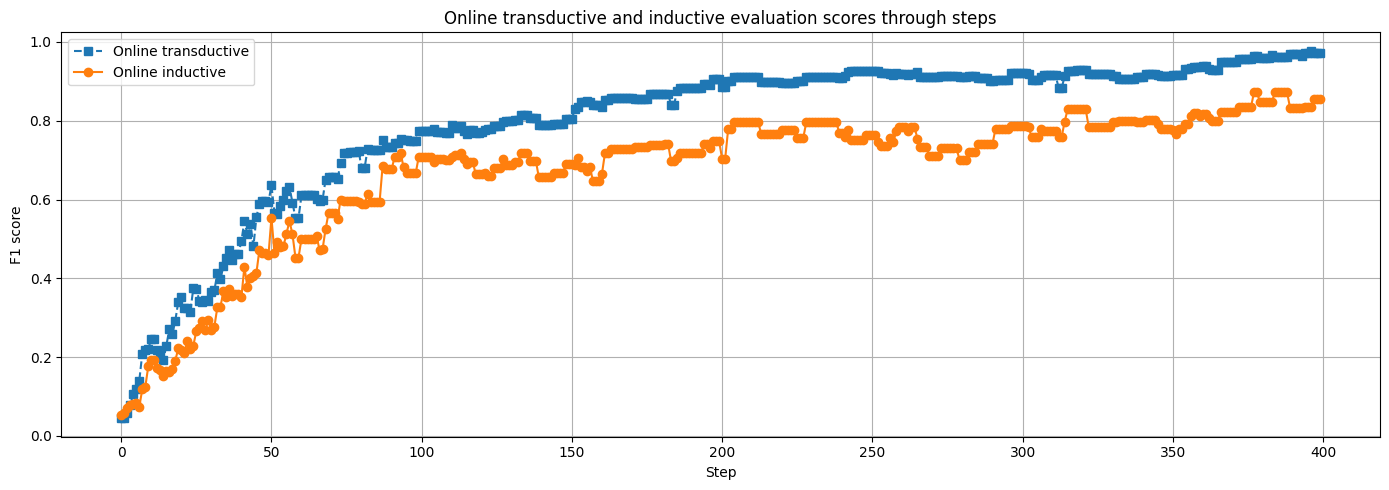

In [61]:
# Plot online learning evaluation through intermediate steps
plt.figure(figsize=(14, 5))
plt.plot(range(len(online_transductive_scores)), online_transductive_scores, marker="s", linestyle="--", label="Online transductive")
plt.plot(range(len(online_inductive_scores)), online_inductive_scores, marker="o", linestyle="-", label="Online inductive")
plt.grid(True)
plt.title("Online transductive and inductive evaluation scores through steps")
plt.xlabel("Step")
plt.ylabel("F1 score")
plt.legend()

plt.tight_layout()
plt.show()

As shown in the plot, both curves exhibit a drop in early stages, after which they recover to high values and stabilize there. We also then observe fluctuations throghout the learning process, with occasional drops and rises that indicate that the online model is, in general, less stable. This confirms our earlier conclusion that online models are less reliable on smaller datasets, where each sample has a bigger impact on the model. On larger datasets, these fluctuations would reduce, so the models would be expected to perform better.